# Demanda de bicicletas: primeiro olhar

Usei os dados horários do [curso da Alura](https://github.com/alura-cursos/data_science_projeto) para entender a demanda antes de tentar prevê-la. A versão do CSV está fixada em `forecast.py`. O interesse aqui é descrever padrões, sem atribuir causalidade ao clima ou ao calendário.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from forecast import DATA_URL, preparar_dados

brutos = pd.read_csv(DATA_URL)
brutos["data_hora"] = pd.to_datetime(brutos["data_hora"])
print(f"{len(brutos):,} medições; {brutos.duplicated().sum()} duplicatas exatas")
print(f"Período: {brutos.data_hora.min():%d/%m/%Y} a {brutos.data_hora.max():%d/%m/%Y}")
print("Valores ausentes:\n", brutos.isna().sum().loc[lambda s: s > 0].to_string())

17,429 medições; 15 duplicatas exatas
Período: 04/01/2015 a 03/01/2017
Valores ausentes:
 temperatura         23
sensacao_termica    23


Importing plotly failed. Interactive plots will not work.


## Antes de somar por dia

Uma soma de 20 horas não é comparável à de um dia com 24 medições. Removi duplicatas exatas e deixei fora da série de previsão os dias incompletos. Não preenchi a demanda ausente com zero. Para explorar clima, calculo médias das medições disponíveis apenas nos dias mantidos.

In [4]:
serie, dias_incompletos = preparar_dados(brutos)
limpos = brutos.drop_duplicates().copy()
limpos["ds"] = limpos["data_hora"].dt.normalize()
clima = limpos.groupby("ds").agg(temperatura=("temperatura", "mean"), umidade=("umidade", "mean"), estacao=("estacao", "first"))
diario = serie.merge(clima, on="ds", validate="one_to_one")
diario["fim_de_semana"] = diario["ds"].dt.dayofweek >= 5
print(f"{len(serie)} dias completos; {dias_incompletos} dias excluídos")
print("Horas observadas nos dias excluídos:\n", limpos.groupby("ds").size().loc[lambda s: s != 24].value_counts().sort_index().to_string())
display(diario.head())

696 dias completos; 34 dias excluídos
Horas observadas nos dias excluídos:
 9      1
12     1
14     1
18     4
19     1
20     2
21     2
22     4
23    18


,ds,y,temperatura,umidade,estacao,fim_de_semana
0,2015-01-04,9234,2.447368,94.270833,Inverno,True
1,2015-01-05,20372,8.125000,80.312500,Inverno,False
2,2015-01-06,20613,7.840909,78.895833,Inverno,False
3,2015-01-08,15601,9.800000,79.312500,Inverno,False
4,2015-01-09,22104,12.729167,74.854167,Inverno,False


## Quanto falta nos dias incompletos?

Há dias com 23 medições e outros com bem menos. A exclusão resolve a comparação dos totais diários, mas reduz a amostra e pode retirar dias atípicos. A distribuição abaixo torna essa decisão auditável.

In [6]:
horas_por_dia = limpos.groupby("ds")["data_hora"].nunique()
faltantes = horas_por_dia.loc[horas_por_dia.ne(24)]
display(faltantes.value_counts().sort_index().rename_axis("horas observadas").to_frame("dias"))
print("Exemplos de datas incompletas:")
display(faltantes.sort_values().head(5).to_frame("horas observadas"))

Exemplos de datas incompletas:


,dias
horas observadas,
9,1
12,1
14,1
18,4
19,1
20,2
21,2
22,4
23,18


,horas observadas
ds,
2016-06-24,9
2016-09-03,12
2016-03-27,14
2015-10-13,18
2016-02-08,18


## Dia útil, fim de semana e passagem do tempo

No conjunto filtrado, a mediana é de **28.152 viagens em dias úteis** e **23.418 nos fins de semana**. O gráfico mostra também uma mudança ao longo dos dois anos: uma divisão aleatória entre treino e teste perderia essa ordem temporal.

,count,median
fim_de_semana,,
False,501,28152.0
True,195,23418.0


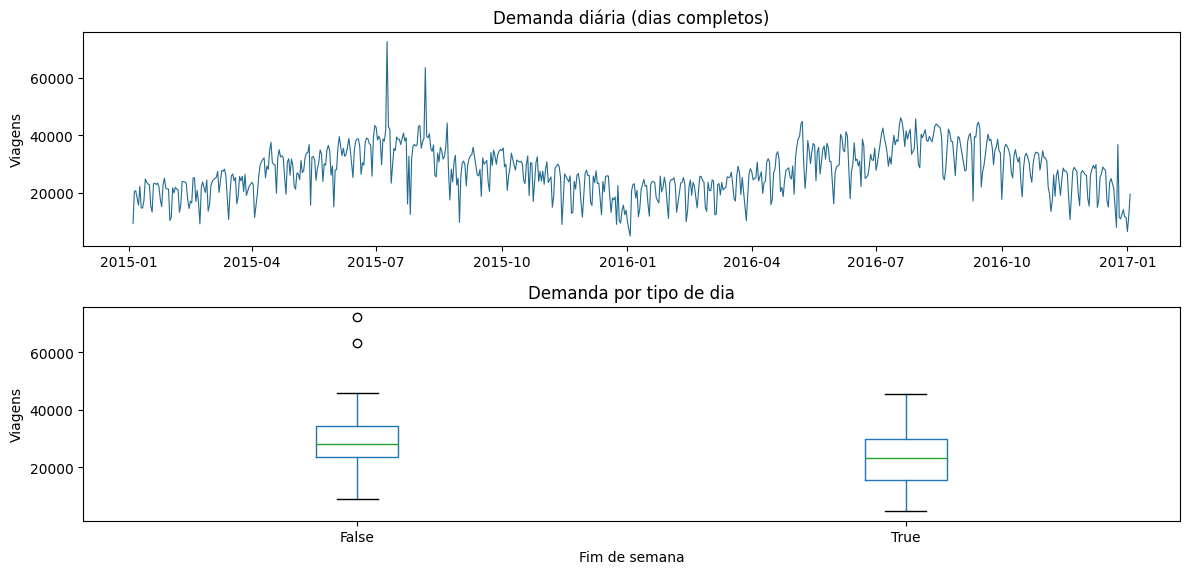

In [8]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(diario["ds"], diario["y"], linewidth=0.8, color="#236b91")
axes[0].set(title="Demanda diária (dias completos)", ylabel="Viagens")
diario.boxplot(column="y", by="fim_de_semana", ax=axes[1], grid=False)
axes[1].set(title="Demanda por tipo de dia", xlabel="Fim de semana", ylabel="Viagens")
fig.suptitle("")
fig.tight_layout()
plt.show()
display(diario.groupby("fim_de_semana")["y"].agg(["count", "median"]))

## Horário do dia

Como a origem é horária, dá para verificar se o perfil intradiário muda entre dias úteis e fins de semana. Uso apenas os dias completos mantidos na série para que a média por hora não misture dias parciais.

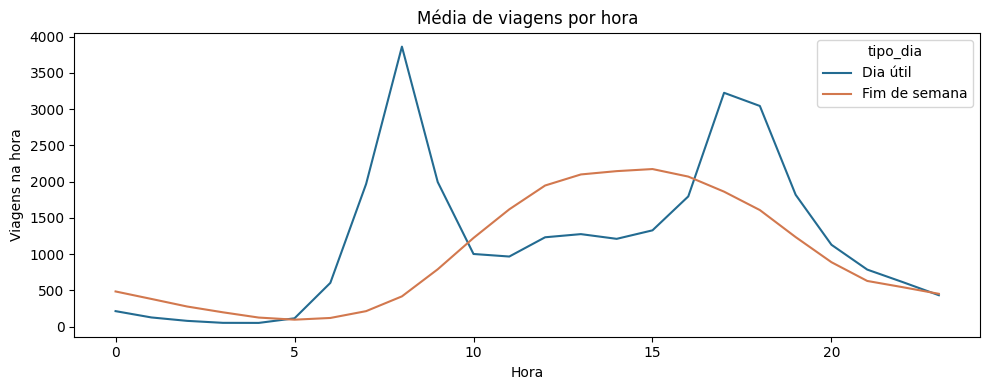

In [10]:
horario = limpos.loc[limpos["ds"].isin(serie["ds"])].copy()
horario["hora"] = horario["data_hora"].dt.hour
horario["tipo_dia"] = horario["ds"].dt.dayofweek.map(lambda dia: "Fim de semana" if dia >= 5 else "Dia útil")
perfil = horario.groupby(["hora", "tipo_dia"])["contagem"].mean().unstack()
ax = perfil.plot(figsize=(10, 4), color={"Dia útil": "#236b91", "Fim de semana": "#d2784e"})
ax.set(title="Média de viagens por hora", xlabel="Hora", ylabel="Viagens na hora")
plt.tight_layout()
plt.show()

## Clima e estação

A mediana diária é maior no verão (35.996) que no inverno (21.275). Temperatura, estação e calendário variam juntos, então estes gráficos não isolam o efeito de nenhum deles.

,count,median
estacao,,
Inverno,175,21275.0
Outono,168,28862.0
Primavera,178,26502.0
Verão,175,35996.0


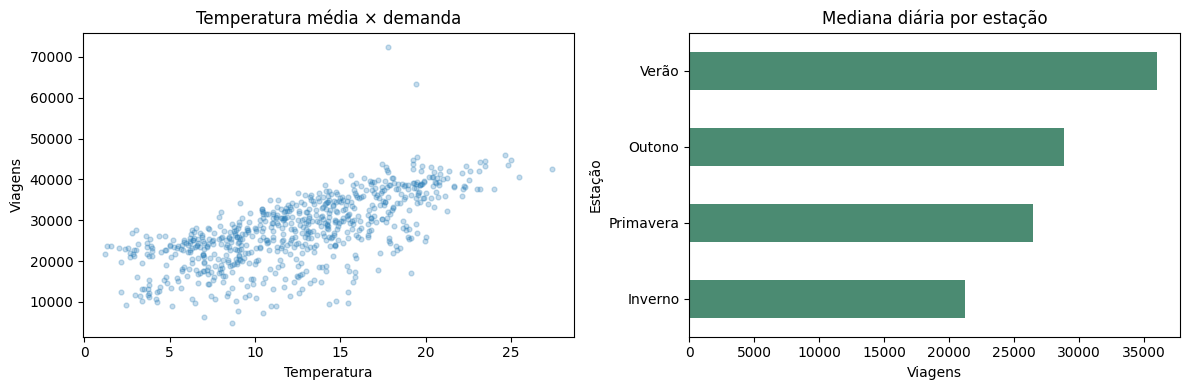

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(diario["temperatura"], diario["y"], alpha=0.25, s=12)
axes[0].set(title="Temperatura média × demanda", xlabel="Temperatura", ylabel="Viagens")
diario.groupby("estacao")["y"].median().sort_values().plot.barh(ax=axes[1], color="#4b8b72")
axes[1].set(title="Mediana diária por estação", xlabel="Viagens", ylabel="Estação")
fig.tight_layout()
plt.show()
display(diario.groupby("estacao")["y"].agg(["count", "median"]))

## Associação numérica, com ressalvas

Temperatura e umidade variam junto com a época do ano. A correlação abaixo resume relações lineares entre médias diárias e demanda, sem controlar estação, tendência ou dia da semana.

In [14]:
display(diario[["y", "temperatura", "umidade"]].corr().round(2).rename(index={"y": "demanda"}, columns={"y": "demanda"}))

,demanda,temperatura,umidade
demanda,1.00,0.69,-0.57
temperatura,0.69,1.00,-0.37
umidade,-0.57,-0.37,1.00


## Decisão para a previsão

A série tem diferenças por dia da semana e por estação. No [notebook de previsão](Forecast_Prophet.ipynb), comparo uma referência semanal simples com três configurações de Prophet. As variáveis de clima ficam fora desses modelos: prever com o clima observado no período de teste seria usar informação que nem sempre estaria disponível no momento da previsão.